# APAC codec results

Lossless verification, byte accounting, stage attribution, a rate-quality sweep against FLAC, the DCT and quantization-step ladders as playable audio, and the float-WAV loader bug. Demo files are three UrbanSound8K clips from `data/raw/fold1`.

Size baseline throughout: the 16-bit PCM payload, `frames x channels x 2` bytes. On-disk file sizes appear only where files are compared directly.

In [1]:
import sys
import tempfile
import time
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display, HTML

from audio_codec.codec.codec import compress, decompress
from audio_codec.codec.format import read_apac
from audio_codec.shared.load_file import load_wav, load_apac, save_apac, save_wav
from audio_codec.config import DEFAULT_SETTINGS, HEADER_STRUCT, LPC_PARAM_SIZE, Predictor, DCTMode
import evaluation

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

TEMP = Path(tempfile.mkdtemp(prefix='apac_notebook_'))


def settings(**overrides):
    return {**DEFAULT_SETTINGS, **overrides}


def pcm_bytes(x):
    # size baseline: 16-bit PCM payload
    return x.size * 2


print('soundfile', sf.__version__, '/ libsndfile', sf.__libsndfile_version__)

soundfile 0.13.1 / libsndfile 1.2.2


## Demo files

Street music (44.1 kHz stereo, tonal), jackhammer (44.1 kHz stereo, broadband impacts), engine idling (48 kHz stereo, FLOAT subtype). The float wav is the loader-bug case in the last section.

In [2]:
CORPUS = ROOT / 'data' / 'raw' / 'fold1'
DEMO_FILES = {
    'street music':  '124489-9-0-12.wav',
    'jackhammer':    '98223-7-9-0.wav',
    'engine idling': '176787-5-0-0.wav',
}
HAVE_CORPUS = (CORPUS / DEMO_FILES['street music']).exists()

audio, meta_info = {}, {}
if HAVE_CORPUS:
    for label, name in DEMO_FILES.items():
        meta, x = load_wav(CORPUS / name)
        audio[label] = (x, meta['samplerate'])
        meta_info[label] = (name, meta['subtype'])
else:
    raise FileNotFoundError("dataset not found at " + str(CORPUS / DEMO_FILES['street music']))
    

for label, (x, sr) in audio.items():
    name, subtype = meta_info[label]
    print(f'{label:14s} {name:22s} {sr:6d} Hz  {len(x):6d} frames  {x.shape[1]} ch  {subtype}')

street music   124489-9-0-12.wav       44100 Hz  176400 frames  2 ch  PCM_16
jackhammer     98223-7-9-0.wav         44100 Hz   65268 frames  2 ch  PCM_16
engine idling  176787-5-0-0.wav        48000 Hz  192000 frames  2 ch  FLOAT


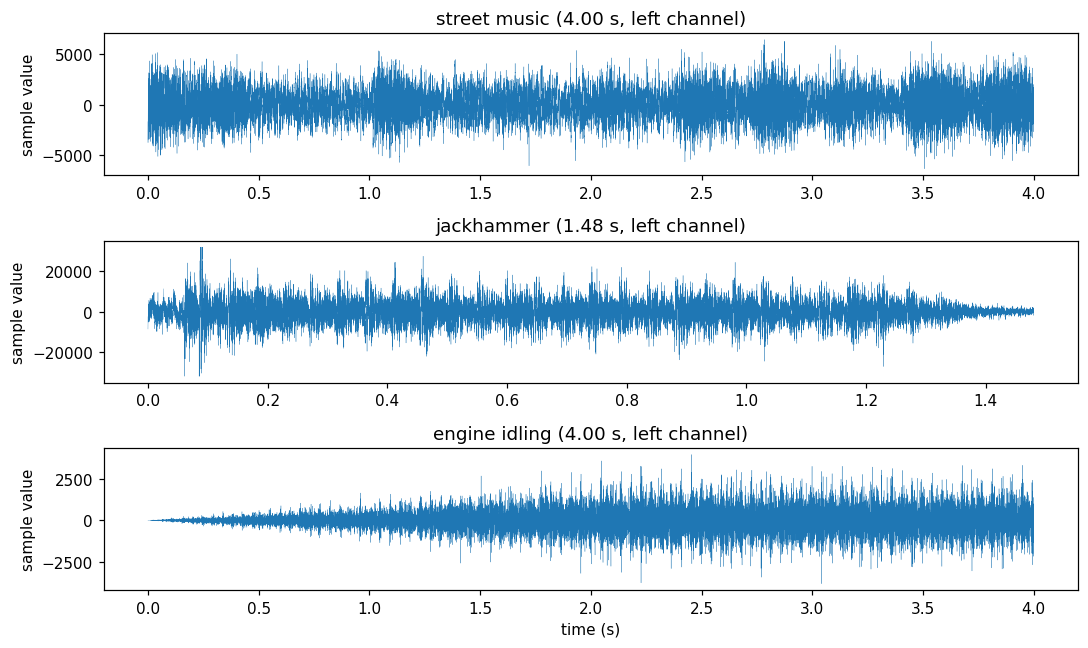

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6))
for ax, (label, (x, sr)) in zip(axes, audio.items()):
    t = np.arange(len(x)) / sr
    ax.plot(t, x[:, 0], lw=0.2)
    ax.set_title(f'{label} ({len(x) / sr:.2f} s, left channel)')
    ax.set_ylabel('sample value')
axes[-1].set_xlabel('time (s)')
fig.tight_layout()
plt.show()

for label, (x, sr) in audio.items():
    n = min(len(x), 6 * sr)
    display(HTML(f'<b>{label}</b> (original, left channel)'))
    display(Audio(data=x[:n, 0] / 32768.0, rate=sr, normalize=False))

## Byte accounting

An APAC file is a 33-byte header, then per 1024-sample block per coding plane: one control byte (raw / Rice k / constant), LPC coefficients when LPC is chosen (2 bytes each), and the entropy-coded residuals. Stereo is two planes, mid and side. The round trip through the container is asserted bit-exact before each size is reported.

The table also carries the two derived rate metrics: average bits per channel-sample (16 = raw PCM) and bitrate in kbit/s.

In [4]:
def rate_metrics(blob, x, sr):
    # derived rate metrics from the compressed size: avg bits per channel-sample, bitrate
    return {'bits_per_sample': len(blob) * 8 / x.size,
            'bitrate_kbps': len(blob) * 8 * sr / x.shape[0] / 1000}


rows = []
for label, (x, sr) in audio.items():
    apac = TEMP / (label.replace(' ', '_') + '.apac')
    save_apac(apac, compress((x, sr), settings()))
    y, _ = decompress(load_apac(apac))
    assert np.array_equal(y, x), label

    blob = load_apac(apac)
    header, payload = read_apac(blob)
    n_blocks = -(-header.frames // (1 << header.block_size_log2))
    control = header.channels * n_blocks
    params = (header.channels * n_blocks * header.predictor_order * LPC_PARAM_SIZE
              if header.predictor == Predictor.LPC else 0)
    rows.append({'file': label, 'pcm_bytes': pcm_bytes(x), 'apac_bytes': len(blob),
                 'header': HEADER_STRUCT.size, 'control': control, 'lpc_params': params,
                 'coded_audio': len(payload) - control - params,
                 'side_info_%': (HEADER_STRUCT.size + control + params) / len(blob) * 100,
                 **rate_metrics(blob, x, sr)})

# LPC is the only setting that puts coefficient bytes on the wire
xl, srl = audio['street music']
blob = compress((xl, srl), settings(predictor=Predictor.LPC, predictor_order=2))
y, _ = decompress(blob)
assert np.array_equal(y, xl)
header, payload = read_apac(blob)
n_blocks = -(-header.frames // (1 << header.block_size_log2))
control = header.channels * n_blocks
params = control * header.predictor_order * LPC_PARAM_SIZE
rows.append({'file': 'street music (lpc-2)', 'pcm_bytes': pcm_bytes(xl), 'apac_bytes': len(blob),
             'header': HEADER_STRUCT.size, 'control': control, 'lpc_params': params,
             'coded_audio': len(payload) - control - params,
             'side_info_%': (HEADER_STRUCT.size + control + params) / len(blob) * 100,
             **rate_metrics(blob, xl, srl)})
display(pd.DataFrame(rows).set_index('file').round(2))

,pcm_bytes,apac_bytes,header,control,lpc_params,coded_audio,side_info_%,bits_per_sample,bitrate_kbps
file,,,,,,,,,
street music,705600,476353,33,346,0,475974,0.08,10.80,952.71
jackhammer,261072,228502,33,128,0,228341,0.07,14.00,1235.15
engine idling,768000,303435,33,376,0,303026,0.13,6.32,606.87
street music (lpc-2),705600,544613,33,346,1384,542850,0.32,12.35,1089.23


## Stages

Pipeline: `load_wav` -> mid/side planes -> (optional DCT) -> 1024-sample blocks -> prediction -> quantize -> Rice coding (raw/constant fallback) -> APAC container.

* Prediction: only residuals are coded. The ladder prices every predictor the format offers (LPC at three orders) and the sweep below prices LPC's full order range; the gap to `none` is the stage's savings.
* Mid/side: stores (L+R)/2 and (L-R)/2 instead of L and R. The side plane is near-constant when channels are correlated; the mid plane costs one extra bit. Applied unconditionally.
* Block mode fallback (Rice k / raw / constant): no block is ever stored larger than its raw PCM.

,none,fixed-2 (default),fixed-4,lpc-1,lpc-2,lpc-8,lms-4
file,,,,,,,
street music,82.7,67.5,73.3,68.0,77.2,77.2,64.8
jackhammer,92.1,87.5,91.1,87.1,86.5,87.6,81.5
engine idling,67.3,39.5,42.8,49.9,66.6,70.1,37.1


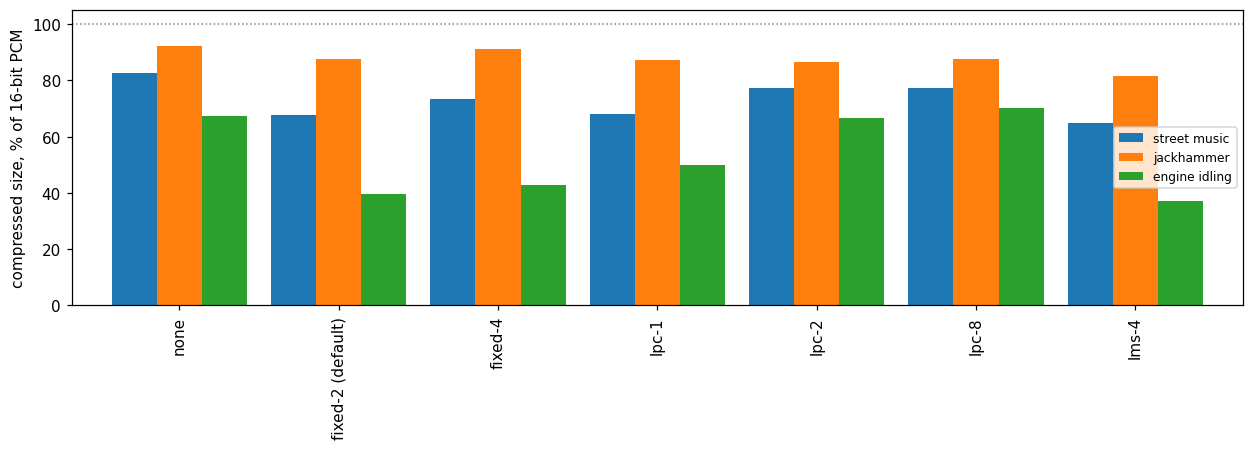

none                 82.7% of PCM   encode  0.05 s   decode  0.09 s
fixed-2 (default)    67.5% of PCM   encode  0.05 s   decode  0.10 s


fixed-4              73.3% of PCM   encode  0.05 s   decode  0.10 s


lpc-1                68.0% of PCM   encode  0.31 s   decode  0.36 s


lpc-2                77.2% of PCM   encode  0.33 s   decode  0.38 s


lpc-8                77.2% of PCM   encode  0.42 s   decode  0.54 s


lms-4                64.8% of PCM   encode  0.82 s   decode  1.69 s

mid/side vs coding the channels separately (payload bytes, header excluded):
street music                       corr +0.63  stereo  476320 B | two monos  454279 B   -> mid/side costs 4.9%
jackhammer                         corr +0.47  stereo  228469 B | two monos  220562 B   -> mid/side costs 3.6%


engine idling                      corr +0.95  stereo  303402 B | two monos  295465 B   -> mid/side costs 2.7%
street music 8k (identical channels) corr +1.00  stereo   48831 B | two monos   88644 B   -> mid/side saves 44.9%


In [5]:
preds = [('none', Predictor.NONE, 0),
         ('fixed-2 (default)', Predictor.FIXED, 2),
         ('fixed-4', Predictor.FIXED, 4),
         ('lpc-1', Predictor.LPC, 1),
         ('lpc-2', Predictor.LPC, 2),
         ('lpc-8', Predictor.LPC, 8),
         ('lms-4', Predictor.LMS, 4)]

rows = []
for label, (x, sr) in audio.items():
    row = {'file': label}
    for name, p, o in preds:
        blob = compress((x, sr), settings(predictor=p, predictor_order=o))
        y, _ = decompress(blob)
        assert np.array_equal(y, x)
        row[name] = len(blob) / pcm_bytes(x) * 100
    rows.append(row)
ladder = pd.DataFrame(rows).set_index('file').round(1)
display(ladder)

ax = ladder.T.plot.bar(figsize=(11.5, 4.2), width=0.85)
ax.axhline(100, color='gray', ls=':', lw=1)
ax.set_ylabel('compressed size, % of 16-bit PCM')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

x, sr = audio['street music']
for name, p, o in preds:
    t0 = time.perf_counter()
    blob = compress((x, sr), settings(predictor=p, predictor_order=o))
    t_enc = time.perf_counter() - t0
    t0 = time.perf_counter()
    decompress(blob)
    t_dec = time.perf_counter() - t0
    print(f'{name:20s} {len(blob) / pcm_bytes(x):5.1%} of PCM   encode {t_enc:5.2f} s   decode {t_dec:5.2f} s')

print()
print('mid/side vs coding the channels separately (payload bytes, header excluded):')
if HAVE_CORPUS:
    meta8, x8 = load_wav(CORPUS / '99180-9-0-0.wav')   # 8 kHz clip with identical channels
    extra = {'street music 8k (identical channels)': (x8, meta8['samplerate'])}
else:
    t8 = np.arange(88200) / 44100
    sig8 = 0.25 * np.sin(2 * np.pi * 220 * t8) + 0.15 * np.sin(2 * np.pi * 277 * t8) + 0.1 * np.sin(2 * np.pi * 440 * t8)
    mono8 = (sig8 * 26000).astype(np.int16)[:, None]
    extra = {'synth chord (identical channels)': (np.concatenate([mono8, mono8], axis=1), 44100)}
for label, (x, sr) in {**audio, **extra}.items():
    corr = float(np.corrcoef(x[:, 0].astype(float), x[:, 1].astype(float))[0, 1])
    stereo = len(compress((x, sr), settings())) - HEADER_STRUCT.size
    monos = sum(len(compress((x[:, c:c + 1], sr), settings())) - HEADER_STRUCT.size for c in range(x.shape[1]))
    print(f'{label:34s} corr {corr:+.2f}  stereo {stereo:7d} B | two monos {monos:7d} B   '
          f'-> mid/side {"saves" if stereo < monos else "costs"} {abs(monos - stereo) / monos:.1%}')

,lpc-1,lpc-2,lpc-4,lpc-8,lpc-16,lpc-32
file,,,,,,
street music,68.0,77.2,76.1,77.2,78.0,79.6
jackhammer,87.1,86.5,87.7,87.6,88.4,89.7
engine idling,49.9,66.6,66.3,70.1,70.4,71.9


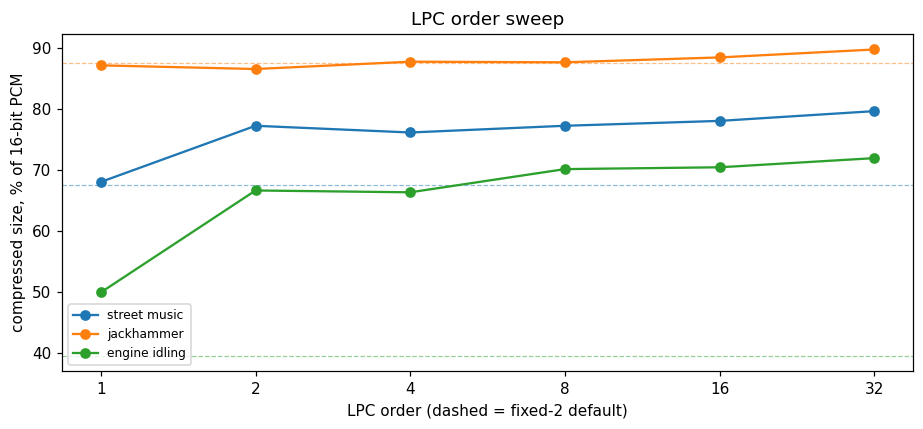

street music   LPC best  lpc-1  68.0%   fixed-2  67.5%   lms-4  64.8%   -> loses to fixed-2, loses to lms-4
jackhammer     LPC best  lpc-2  86.5%   fixed-2  87.5%   lms-4  81.5%   -> beats fixed-2, loses to lms-4
engine idling  LPC best  lpc-1  49.9%   fixed-2  39.5%   lms-4  37.1%   -> loses to fixed-2, loses to lms-4
side information: 2 B per coefficient per block plane, so order 32 pays ~3.1% of PCM per plane before any fit gain


In [6]:
orders = [1, 2, 4, 8, 16, 32]
rows = []
for label, (x, sr) in audio.items():
    row = {'file': label}
    for o in orders:
        blob = compress((x, sr), settings(predictor=Predictor.LPC, predictor_order=o))
        y, _ = decompress(blob)
        assert np.array_equal(y, x)
        row[f'lpc-{o}'] = len(blob) / pcm_bytes(x) * 100
    rows.append(row)
lpc_sweep = pd.DataFrame(rows).set_index('file').round(1)
display(lpc_sweep)

fig, ax = plt.subplots(figsize=(8.5, 4))
for i, label in enumerate(lpc_sweep.index):
    ax.plot(orders, lpc_sweep.loc[label], 'o-', color=f'C{i}', label=label)
    ax.axhline(ladder.loc[label, 'fixed-2 (default)'], color=f'C{i}', ls='--', lw=0.8, alpha=0.5)
ax.set_xscale('log', base=2)
ax.set_xticks(orders)
ax.set_xticklabels([str(o) for o in orders])
ax.set_xlabel('LPC order (dashed = fixed-2 default)')
ax.set_ylabel('compressed size, % of 16-bit PCM')
ax.set_title('LPC order sweep')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for label in lpc_sweep.index:
    row = lpc_sweep.loc[label]
    best_o, best = row.idxmin(), row.min()
    f2 = ladder.loc[label, 'fixed-2 (default)']
    lm = ladder.loc[label, 'lms-4']
    print(f"{label:14s} LPC best {best_o:>6s} {best:5.1f}%   fixed-2 {f2:5.1f}%   lms-4 {lm:5.1f}%   "
          f"-> {'beats' if best < f2 else 'loses to'} fixed-2, {'beats' if best < lm else 'loses to'} lms-4")
print('side information: 2 B per coefficient per block plane, so order 32 pays ~3.1% of PCM per plane before any fit gain')


## Rate-quality: quantization step

`quant_step` rounds prediction residuals to multiples of the step. The encoder predicts from its own reconstructed samples, so the error is bounded by step/2 per sample and cannot accumulate.

SNR = 10 log10( sum(x^2) / sum((x - y)^2) ), computed on the int16 samples; bit-exact decode is SNR = inf. FLAC (libsndfile, PCM_16) is the lossless reference.

Rate is reported three ways: % of PCM, average bits per sample (16 = raw PCM), and bitrate in kbit/s - all derived from the same compressed sizes.

size, % of 16-bit PCM:


file,engine idling,jackhammer,street music
step,,,
1,39.5,87.5,67.5
2,33.4,81.2,61.2
4,27.6,75.0,55.0
8,22.3,68.7,48.7
16,17.7,62.4,42.4
32,14.1,56.1,36.2


SNR, dB (inf = bit exact):


file,engine idling,jackhammer,street music
step,,,
1,inf,inf,inf
2,62.5,80.1,70.5
4,57.7,75.4,65.7
8,52.0,69.7,60.1
16,46.1,63.8,54.2
32,40.2,57.8,48.2


average bits per sample (16 = raw PCM):


file,engine idling,jackhammer,street music
step,,,
1,6.32,14.00,10.80
2,5.35,13.00,9.80
4,4.42,12.00,8.79
8,3.56,10.99,7.79
16,2.82,9.99,6.79
32,2.26,8.98,5.79


bitrate, kbit/s:


file,engine idling,jackhammer,street music
step,,,
1,607.0,1235.0,953.0
2,514.0,1147.0,864.0
4,424.0,1058.0,776.0
8,342.0,969.0,687.0
16,271.0,881.0,599.0
32,217.0,792.0,510.0


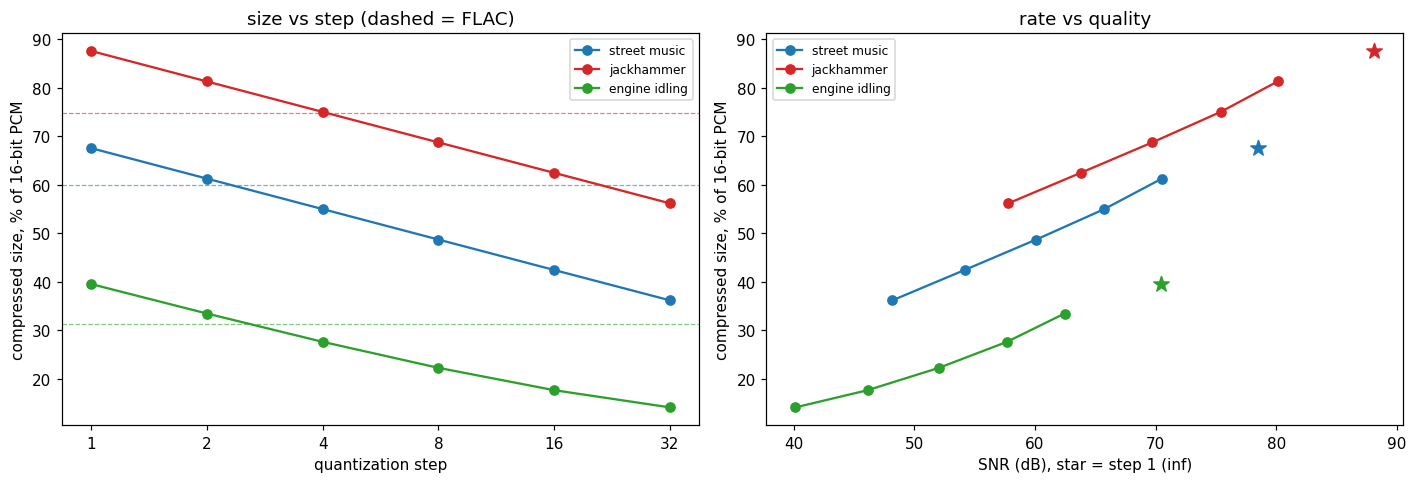

first lossy step below FLAC:
  street music   FLAC  60.0%  ->  step  4 (55.0%, SNR 65.7 dB)
  jackhammer     FLAC  74.8%  ->  step  8 (68.7%, SNR 69.7 dB)
  engine idling  FLAC  31.3%  ->  step  4 (27.6%, SNR 57.7 dB)


In [7]:
def flac_bytes(x, sr, tag):
    p = TEMP / (tag.replace(' ', '_') + '.flac')
    sf.write(p, x, sr, format='FLAC', subtype='PCM_16')
    return p.stat().st_size


steps = [1, 2, 4, 8, 16, 32]
rows = []
flac_pct = {}
for label, (x, sr) in audio.items():
    flac_pct[label] = flac_bytes(x, sr, label) / pcm_bytes(x) * 100
    for st in steps:
        blob = compress((x, sr), settings(quant_step=st))
        y, _ = decompress(blob)
        rows.append({'file': label, 'step': st,
                     'size_%pcm': len(blob) / pcm_bytes(x) * 100,
                     'snr_db': evaluation.snr_db(x, y),
                     'max_err_lsb': int(np.abs(y.astype(np.int32) - x.astype(np.int32)).max()),
                     'bit_exact': bool(np.array_equal(y, x)),
                     'bits_per_sample': len(blob) * 8 / x.size,
                     'bitrate_kbps': len(blob) * 8 * sr / x.shape[0] / 1000})
sweep = pd.DataFrame(rows)
print('size, % of 16-bit PCM:')
display(sweep.pivot(index='step', columns='file', values='size_%pcm').round(1))
print('SNR, dB (inf = bit exact):')
display(sweep.pivot(index='step', columns='file', values='snr_db').round(1))
print('average bits per sample (16 = raw PCM):')
display(sweep.pivot(index='step', columns='file', values='bits_per_sample').round(2))
print('bitrate, kbit/s:')
display(sweep.pivot(index='step', columns='file', values='bitrate_kbps').round(0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
colors = dict(zip(audio, ('C0', 'C3', 'C2')))
for label, (x, sr) in audio.items():
    sub = sweep[sweep.file == label]
    ax1.plot(sub['step'], sub['size_%pcm'], 'o-', color=colors[label], label=label)
    ax1.axhline(flac_pct[label], color=colors[label], ls='--', lw=0.8, alpha=0.6)
    finite = sub[np.isfinite(sub.snr_db)]
    ax2.plot(finite.snr_db, finite['size_%pcm'], 'o-', color=colors[label], label=label)
    y1 = float(sub.loc[sub.step == 1, 'size_%pcm'].iloc[0])
    ax2.scatter([finite.snr_db.max() + 8], [y1], marker='*', s=110, color=colors[label])
ax1.set_xscale('log', base=2)
ax1.set_xticks(steps)
ax1.set_xticklabels([str(s) for s in steps])
ax1.set_xlabel('quantization step')
ax1.set_ylabel('compressed size, % of 16-bit PCM')
ax1.set_title('size vs step (dashed = FLAC)')
ax1.legend(fontsize=8)
ax2.set_xlabel('SNR (dB), star = step 1 (inf)')
ax2.set_ylabel('compressed size, % of 16-bit PCM')
ax2.set_title('rate vs quality')
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

print('first lossy step below FLAC:')
for label, (x, sr) in audio.items():
    sub = sweep[(sweep.file == label) & (sweep.step > 1)]
    under = sub[sub['size_%pcm'] < flac_pct[label]]
    if len(under):
        first = under.iloc[0]
        print(f"  {label:14s} FLAC {flac_pct[label]:5.1f}%  ->  step {int(first.step):2d} "
              f"({first['size_%pcm']:.1f}%, SNR {first.snr_db:.1f} dB)")
    else:
        print(f"  {label:14s} FLAC {flac_pct[label]:5.1f}%  ->  none up to step 32")

## Corpus sweep

`quant_step` 1 to 32 over the corpus, fixed-2 defaults, FLAC (libsndfile, PCM_16) as the lossless reference. The clip set, every size and every SNR in this section are computed in this cell. Median average bits per sample and median bitrate (kbit/s) join the per-step summary.

873 fold1 clips, taking every 14-th by sorted name -> 60 files


   1/60  101415-3-0-2.wav


   2/60  103074-7-1-2.wav


   3/60  103074-7-4-4.wav


   4/60  103258-5-0-19.wav


   5/60  105415-2-0-4.wav


... (53 outputs left out)

  59/60  78360-4-0-15.wav


  60/60  78360-4-0-7.wav


,file,pcm_bytes,flac_bytes,apac1,apac2,apac4,apac8,apac16,apac32
0,101415-3-0-2.wav,384000,121029,133439,110941,90645,73439,60025,49470
1,103074-7-1-2.wav,768000,437748,501773,453634,405527,357417,309396,261623
2,103074-7-4-4.wav,768000,428939,500218,452086,403969,355874,307877,260163
3,103258-5-0-19.wav,768000,253399,299338,251503,204260,159849,122168,97191
4,105415-2-0-4.wav,768000,414542,470347,422221,374109,326016,278030,230526
5,108362-2-0-11.wav,768000,403645,487871,439731,391624,343528,295492,247741
6,113205-5-1-5.wav,1536000,327736,409999,327699,259729,213997,183320,160221
7,118279-8-0-1.wav,768000,240445,291056,243296,196586,153343,117585,94968
8,118963-3-0-0.wav,99740,31422,46702,40508,34187,25997,19023,16478
9,124489-9-0-18.wav,705600,400263,450325,406037,361754,317486,273290,229415


lossless step 1: 60/60 bit-exact
lossless size vs PCM: APAC 51.6%, FLAC 42.1% (bytes-weighted)
step | %PCM med | x FLAC med | SNR med/min dB | bits/sample med | kbit/s med
   1 |     55.1 |       1.22 |    inf /   inf |            8.81 |       797
   2 |     48.8 |       1.08 |   73.5 /  32.1 |            7.81 |       692
   4 |     42.5 |       0.93 |   68.8 /  27.3 |            6.81 |       600
   8 |     36.3 |       0.81 |   63.3 /  21.7 |            5.81 |       512
  16 |     30.1 |       0.70 |   57.4 /  15.8 |            4.81 |       432
  32 |     24.4 |       0.59 |   51.4 /  10.3 |            3.90 |       355
lossless bitrate medians: APAC 797 kbit/s, FLAC 648 kbit/s
first step with median size below FLAC: 4


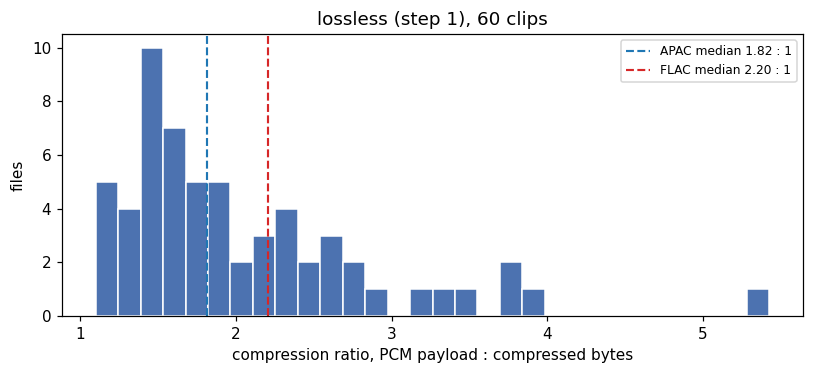

In [8]:
steps = [1, 2, 4, 8, 16, 32]


def sweep_row(name, x, sr):
    rec = {'file': name, 'pcm_bytes': pcm_bytes(x), 'flac_bytes': flac_bytes(x, sr, name),
           'samples': int(x.size), 'frames': int(x.shape[0]), 'samplerate': int(sr)}
    for st in steps:
        blob = compress((x, sr), settings(quant_step=st))
        y, _ = decompress(blob)
        rec[f'apac{st}'] = len(blob)
        rec[f'snr{st}'] = evaluation.snr_db(x, y)
    return rec


rows = []
if HAVE_CORPUS:
    wavs = sorted(CORPUS.glob('*.wav'))
    stride = max(1, len(wavs) // 60)
    files = wavs[::stride][:60]
    print(f'{len(wavs)} fold1 clips, taking every {stride}-th by sorted name -> {len(files)} files')
    for i, path in enumerate(files, 1):
        meta, x = load_wav(path)
        rows.append(sweep_row(path.name, x, meta['samplerate']))
        print(f'  {i:2d}/{len(files)}  {path.name}')
else:
    print('corpus absent, sweeping the demo set instead')
    rows = [sweep_row(label, x, sr) for label, (x, sr) in audio.items()]

cdf = pd.DataFrame(rows)
display(cdf[['file', 'pcm_bytes', 'flac_bytes'] + [f'apac{s}' for s in steps]])

pcm = cdf['pcm_bytes'].to_numpy(float)
flac = cdf['flac_bytes'].to_numpy(float)
sizes = {s: cdf[f'apac{s}'].to_numpy(float) for s in steps}
snrs = {s: cdf[f'snr{s}'].to_numpy(float) for s in steps}
durations = cdf['frames'].to_numpy(float) / cdf['samplerate'].to_numpy(float)
samples = cdf['samples'].to_numpy(float)
bps = {s: sizes[s] * 8 / samples for s in steps}        # avg bits per channel-sample
kbps = {s: sizes[s] * 8 / durations / 1000 for s in steps}  # kbit/s
flac_kbps = flac * 8 / durations / 1000

print(f"lossless step 1: {(snrs[1] == np.inf).sum()}/{len(cdf)} bit-exact")
print(f'lossless size vs PCM: APAC {sizes[1].sum() / pcm.sum():.1%}, FLAC {flac.sum() / pcm.sum():.1%} (bytes-weighted)')
print('step | %PCM med | x FLAC med | SNR med/min dB | bits/sample med | kbit/s med')
for s in steps:
    print(f'{s:4d} | {np.median(sizes[s] / pcm) * 100:8.1f} | {np.median(sizes[s] / flac):10.2f} | '
          f'{np.median(snrs[s]):6.1f} / {np.min(snrs[s]):5.1f} | '
          f'{np.median(bps[s]):15.2f} | {np.median(kbps[s]):9.0f}')
print(f'lossless bitrate medians: APAC {np.median(kbps[1]):.0f} kbit/s, '
      f'FLAC {np.median(flac_kbps):.0f} kbit/s')
under = [s for s in steps[1:] if np.median(sizes[s] / flac) < 1]
print('first step with median size below FLAC:', under[0] if under else f'none up to step {steps[-1]}')

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.hist(pcm / sizes[1], bins=30, color='#4c72b0', edgecolor='white')
ax.axvline(np.median(pcm / sizes[1]), color='C0', ls='--', lw=1.4,
           label=f'APAC median {np.median(pcm / sizes[1]):.2f} : 1')
ax.axvline(np.median(pcm / flac), color='C3', ls='--', lw=1.4,
           label=f'FLAC median {np.median(pcm / flac):.2f} : 1')
ax.set_xlabel('compression ratio, PCM payload : compressed bytes')
ax.set_ylabel('files')
ax.set_title(f'lossless (step 1), {len(cdf)} clips')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Full-release sweep

`quant_step` 1 to 32 over every excerpt in the dataset - all 10 folds, 8732 clips - with the same fixed-2 defaults, FLAC anchor and metrics as the fold1 sample above, so the report-level numbers rest on the full release rather than the 60-file sample. The clips are processed one at a time, so the release is never in memory all at once.


In [ ]:
# Full-release sweep: the corpus sweep above over every excerpt in the
# dataset (all 10 folds) instead of the every-14th fold1 sample.
from concurrent.futures import ProcessPoolExecutor

SWEEP_WORKERS = 4

# Windows pools only pickle functions from importable modules, so the
# worker - same metrics as sweep_row above - lives in a scratch module.
worker_src = '''
import sys
import tempfile
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))

import numpy as np
import soundfile as sf

from audio_codec.codec.codec import compress, decompress
from audio_codec.config import DEFAULT_SETTINGS
from audio_codec.shared.load_file import load_wav
import evaluation

STEPS = [1, 2, 4, 8, 16, 32]
TMP = Path(tempfile.mkdtemp(prefix='apac_full_sweep_'))


def sweep(path_str):
    # one clip at a time: load, FLAC anchor, encode/decode per step, SNR
    path = Path(path_str)
    meta, x = load_wav(path)
    sr = int(meta['samplerate'])
    fp = TMP / (path.name + '.flac')
    sf.write(fp, x, sr, format='FLAC', subtype='PCM_16')
    flac = fp.stat().st_size
    fp.unlink()
    rec = {'file': path.name, 'fold': path.parent.name, 'samplerate': sr,
           'frames': int(x.shape[0]), 'samples': int(x.size),
           'pcm_bytes': int(x.size * 2), 'flac_bytes': int(flac)}
    for st in STEPS:
        blob = compress((x, sr), {**DEFAULT_SETTINGS, 'quant_step': st})
        y, _ = decompress(blob)
        rec[f'apac{st}'] = len(blob)
        rec[f'snr{st}'] = float(evaluation.snr_db(x, y))
    return rec
'''
(TEMP / 'full_sweep_worker.py').write_text(worker_src)
sys.path.insert(0, str(TEMP))
import full_sweep_worker

all_wavs = sorted(p for d in sorted((ROOT / 'data' / 'raw').glob('fold*'))
                  for p in d.glob('*.wav'))
fold_names = sorted({p.parent.name for p in all_wavs})
print(f'{len(fold_names)} folds, {len(all_wavs)} clips, {SWEEP_WORKERS} workers')

full_rows = []
t0 = time.perf_counter()
with ProcessPoolExecutor(max_workers=SWEEP_WORKERS) as pool:
    for i, rec in enumerate(pool.map(full_sweep_worker.sweep,
                                      (str(p) for p in all_wavs), chunksize=16), 1):
        full_rows.append(rec)
        if i % 250 == 0 or i == len(all_wavs):
            print(f'  {i}/{len(all_wavs)}  ({time.perf_counter() - t0:.0f}s)')
print(f'swept {len(full_rows)} clips in {time.perf_counter() - t0:.0f}s')

fdf = pd.DataFrame(full_rows)
fpcm = fdf['pcm_bytes'].to_numpy(float)
fflac = fdf['flac_bytes'].to_numpy(float)
fsizes = {s: fdf[f'apac{s}'].to_numpy(float) for s in steps}
fsnrs = {s: fdf[f'snr{s}'].to_numpy(float) for s in steps}
fdurations = fdf['frames'].to_numpy(float) / fdf['samplerate'].to_numpy(float)
fsamples = fdf['samples'].to_numpy(float)
fbps = {s: fsizes[s] * 8 / fsamples for s in steps}            # avg bits per channel-sample
fkbps = {s: fsizes[s] * 8 / fdurations / 1000 for s in steps}  # kbit/s
fflac_kbps = fflac * 8 / fdurations / 1000

print(f"lossless step 1: {(fsnrs[1] == np.inf).sum()}/{len(fdf)} bit-exact")
print(f'lossless size vs PCM: APAC {fsizes[1].sum() / fpcm.sum():.1%}, FLAC {fflac.sum() / fpcm.sum():.1%} (bytes-weighted)')
print('step | %PCM med | x FLAC med | SNR med/min dB | bits/sample med | kbit/s med')
for s in steps:
    print(f'{s:4d} | {np.median(fsizes[s] / fpcm) * 100:8.1f} | {np.median(fsizes[s] / fflac):10.2f} | '
          f'{np.median(fsnrs[s]):6.1f} / {np.min(fsnrs[s]):5.1f} | '
          f'{np.median(fbps[s]):15.2f} | {np.median(fkbps[s]):9.0f}')
print(f'lossless bitrate medians: APAC {np.median(fkbps[1]):.0f} kbit/s, '
      f'FLAC {np.median(fflac_kbps):.0f} kbit/s')
funder = [s for s in steps[1:] if np.median(fsizes[s] / fflac) < 1]
print('first step with median size below FLAC:', funder[0] if funder else f'none up to step {steps[-1]}')


10 folds, 8732 clips, 4 workers


  250/8732  (233s)


  500/8732  (532s)


  750/8732  (944s)


  1000/8732  (1452s)


  1250/8732  (1789s)


... (26 outputs left out)

  8000/8732  (7581s)


  8250/8732  (7758s)


  8500/8732  (7969s)


  8732/8732  (8138s)
swept 8732 clips in 8138s
lossless step 1: 8732/8732 bit-exact
lossless size vs PCM: APAC 57.0%, FLAC 47.4% (bytes-weighted)
step | %PCM med | x FLAC med | SNR med/min dB | bits/sample med | kbit/s med
   1 |     59.0 |       1.18 |    inf /   inf |            9.43 |       840
   2 |     52.7 |       1.05 |   73.0 /  22.4 |            8.43 |       750
   4 |     46.4 |       0.93 |   67.6 /  17.6 |            7.42 |       658
   8 |     40.1 |       0.81 |   62.0 /  12.0 |            6.42 |       566
  16 |     34.0 |       0.70 |   56.2 /   6.5 |            5.44 |       475
  32 |     28.0 |       0.59 |   50.2 /   2.3 |            4.49 |       393
lossless bitrate medians: APAC 840 kbit/s, FLAC 687 kbit/s
first step with median size below FLAC: 4


## DCT pre-shaping

The header carries one `dct_param` (uint32) and a single encoder-side mode beyond OFF: QUANTIZE, the JPEG-style quality knob that was the intent from the start (an earlier hard CUTOFF wall and a per-mille ATTENUATE scale were retired - a frequency wall is only defensible at 15 kHz and up, and a global scale is no rate knob at all). Each window goes through a forward DCT, every bin snaps to a multiple of a per-bin step from a frequency-weighted base table (1 at DC, window_size/32 per bin index, about 32700 at the top of the default 1024 window) scaled libjpeg-style by `dct_param` as quality 1-100, then the inverse DCT rounds back to int32. Lower quality coarsens the high end first, no frequency is ever walled off, and 100 keeps every step at 1 - only transform rounding remains, bit-exact on this clip. The table is derived from `dct_param` and the window size, never stored, so the wire format keeps its single uint32 and the decoder stays a no-op. SNR under-reads the shaping: the error concentrates in the high frequencies, where hearing is least sensitive. The trial prices the quality ladder against `quant_step` on the tonal and the broadband clip, reporting size as % of PCM plus the derived average bits per sample and bitrate. The players below make both knobs audible on the tonal clip: the original, two DCT qualities, and four `quant_step` variants from 4 (the CLI default lossy step) to 256 - unlike the DCT, whose error concentrates where hearing is least sensitive, the step ladder's error is broadband, so the coarse steps are the audibly rough ones.

,size_%pcm,snr_db,max_err_lsb,bit_exact,bits_per_sample,bitrate_kbps
variant,,,,,,
"original (dct off, lossless)",67.5,inf,0,True,10.8,952.7
quantize q=100,67.5,inf,0,True,10.8,952.7
quantize q=90,67.5,41.7,143,False,10.8,953.2
quantize q=50,67.5,30.7,646,False,10.8,953.0
quantize q=10,65.2,21.1,1047,False,10.4,920.7
quant_step 2 (rate knob),61.2,70.5,1,False,9.8,864.1
quant_step 4 (rate knob),55.0,65.7,2,False,8.8,775.6
quant_step 8 (rate knob),48.7,60.1,4,False,7.8,687.0
quant_step 16 (rate knob),42.4,54.2,8,False,6.8,598.5


,size_%pcm,snr_db,bits_per_sample,bitrate_kbps
jackhammer,,,,
quantize q=50,87.5,38.1,14.0,1235.5
quantize q=10,87.6,26.2,14.0,1236.1
quant_step 4 (rate knob),75.0,75.4,12.0,1058.0
quant_step 8 (rate knob),68.7,69.7,11.0,969.4
quant_step 16 (rate knob),62.4,63.8,10.0,880.9


quality 100 is transparent and the ladder coarsens the high end first, but even q=10 (65.2% at 21.1 dB) loses to quant_step 8 (48.7% at 60.1 dB); quant_step stays the rate-quality knob


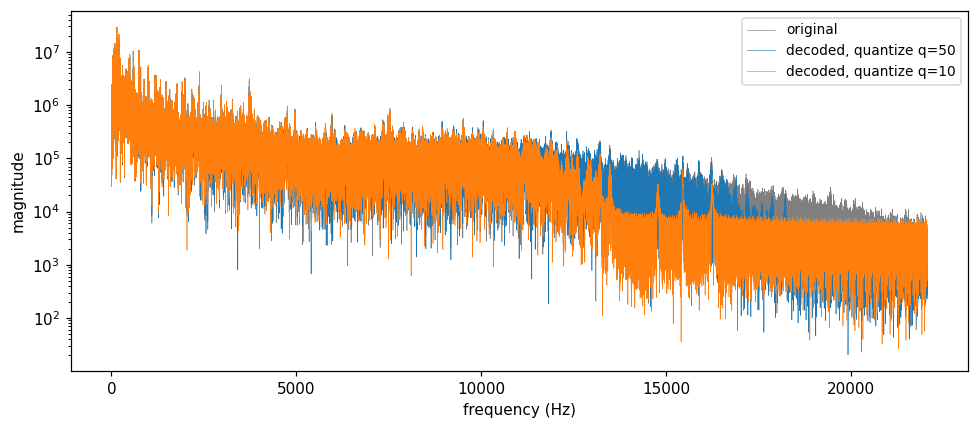

In [9]:
x, sr = audio['street music']
variants = [('original (dct off, lossless)', settings()),
            ('quantize q=100', settings(dct_mode=DCTMode.QUANTIZE, dct_param=100, dct_window_size=1024)),
            ('quantize q=90', settings(dct_mode=DCTMode.QUANTIZE, dct_param=90, dct_window_size=1024)),
            ('quantize q=50', settings(dct_mode=DCTMode.QUANTIZE, dct_param=50, dct_window_size=1024)),
            ('quantize q=10', settings(dct_mode=DCTMode.QUANTIZE, dct_param=10, dct_window_size=1024)),
            ('quant_step 2 (rate knob)', settings(quant_step=2)),
            ('quant_step 4 (rate knob)', settings(quant_step=4)),
            ('quant_step 8 (rate knob)', settings(quant_step=8)),
            ('quant_step 16 (rate knob)', settings(quant_step=16)),
            ('quant_step 32 (rate knob)', settings(quant_step=32)),
            ('quant_step 64 (rate knob)', settings(quant_step=64)),
            ('quant_step 128 (rate knob)', settings(quant_step=128)),
            ('quant_step 256 (rate knob)', settings(quant_step=256)),
            ('quant_step 512 (rate knob)', settings(quant_step=512)),
            ('quant_step 1024 (rate knob)', settings(quant_step=1024))]

rows, decoded = [], {}
for name, over in variants:
    blob = compress((x, sr), over)
    y, _ = decompress(blob)
    decoded[name] = y
    rows.append({'variant': name, 'size_%pcm': len(blob) / pcm_bytes(x) * 100,
                 'snr_db': evaluation.snr_db(x, y),
                 'max_err_lsb': int(np.abs(y.astype(np.int32) - x.astype(np.int32)).max()),
                 'bit_exact': bool(np.array_equal(y, x)),
                 'bits_per_sample': len(blob) * 8 / x.size,
                 'bitrate_kbps': len(blob) * 8 * sr / x.shape[0] / 1000})
display(pd.DataFrame(rows).set_index('variant').round(1))

jx, jsr = audio['jackhammer']
jrows = []
for name, over in [('quantize q=50', settings(dct_mode=DCTMode.QUANTIZE, dct_param=50, dct_window_size=1024)),
                   ('quantize q=10', settings(dct_mode=DCTMode.QUANTIZE, dct_param=10, dct_window_size=1024)),
                   ('quant_step 4 (rate knob)', settings(quant_step=4)),
                   ('quant_step 8 (rate knob)', settings(quant_step=8)),
                   ('quant_step 16 (rate knob)', settings(quant_step=16)),]:
    blob = compress((jx, jsr), over)
    y, _ = decompress(blob)
    jrows.append({'jackhammer': name, 'size_%pcm': len(blob) / pcm_bytes(jx) * 100,
                  'snr_db': evaluation.snr_db(jx, y),
                  'bits_per_sample': len(blob) * 8 / jx.size,
                  'bitrate_kbps': len(blob) * 8 * jsr / jx.shape[0] / 1000})
display(pd.DataFrame(jrows).set_index('jackhammer').round(1))

q10 = next(r for r in rows if r['variant'] == 'quantize q=10')
s8 = next(r for r in rows if r['variant'] == 'quant_step 8 (rate knob)')
print(f"quality 100 is transparent and the ladder coarsens the high end first, but even q=10 "
      f"({q10['size_%pcm']:.1f}% at {q10['snr_db']:.1f} dB) loses to quant_step 8 "
      f"({s8['size_%pcm']:.1f}% at {s8['snr_db']:.1f} dB); quant_step stays the rate-quality knob")

players = ['original (dct off, lossless)', 'quantize q=50', 'quantize q=10',
           'quant_step 4 (rate knob)', 'quant_step 16 (rate knob)',
           'quant_step 64 (rate knob)', 'quant_step 256 (rate knob)']
n = min(len(x), 3 * sr)
for name in players:
    display(HTML(f'<b>street music</b> - {name}'))
    display(Audio(data=decoded[name][:n, 0] / 32768.0, rate=sr, normalize=False))

freqs = np.fft.rfftfreq(n, 1 / sr)
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(freqs, np.abs(np.fft.rfft(x[:n, 0].astype(np.float64))), lw=0.4, color='gray', label='original')
ax.semilogy(freqs, np.abs(np.fft.rfft(decoded['quantize q=50'][:n, 0].astype(np.float64))), lw=0.4,
            color='C0', label='decoded, quantize q=50')
ax.semilogy(freqs, np.abs(np.fft.rfft(decoded['quantize q=10'][:n, 0].astype(np.float64))), lw=0.4,
            color='C1', label='decoded, quantize q=10')
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('magnitude')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### What we hear

The players above play the same three seconds of street music: the lossless original, two DCT qualities, and quantization steps 4, 16, 64 and 256.

TODO: both authors listen and write here where the difference from the original becomes noticeable, and what it sounds like.


## Float WAV loader bug

`sf.read(dtype='int16')` returns all zeros for FLOAT wavs on soundfile 0.13.1 / libsndfile 1.2.2. The first `load_wav` used that call for every input, so float sources loaded as silence. The fix routes by subtype: int16 read for PCM_U8/PCM_16, u-law, a-law, ADPCM; float64 read plus round-and-clip for wider subtypes, error bounded at 0.5 LSB.

float sine, old path:   0/44100 samples non-zero
float sine, fixed path:  44080/44100 samples non-zero
(soundfile 0.13.1 / libsndfile 1.2.2; failure observed on libsndfile 1.2.2)



engine idling (FLOAT): old path 0/384000 non-zero, fixed path 382913/384000 non-zero
cast cost of the fixed path: max |err| 0.500 LSB (bound 0.5 LSB)


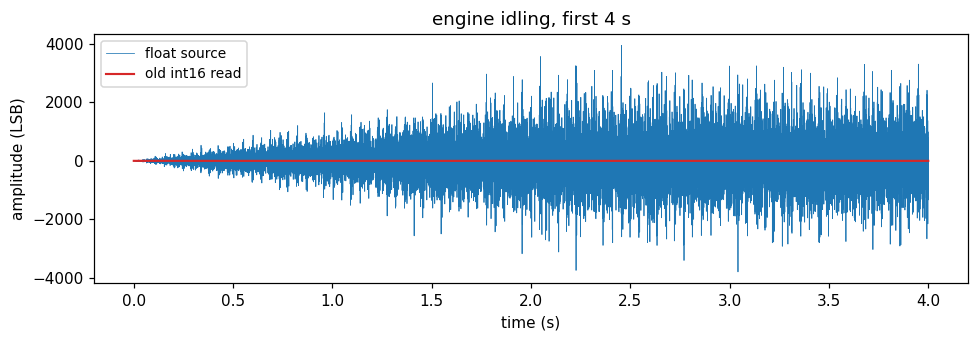

In [10]:
sr = 44100
t = np.arange(sr) / sr
sine = (0.4 * np.sin(2 * np.pi * 440 * t))[:, None]

pf = TEMP / 'sine_float.wav'
sf.write(pf, sine, sr, subtype='FLOAT')

old_read, _ = sf.read(pf, dtype='int16', always_2d=True)   # what load_wav used to do
_, fixed = load_wav(pf)

print(f'float sine, old path:   {np.count_nonzero(old_read)}/{old_read.size} samples non-zero')
print(f'float sine, fixed path:  {np.count_nonzero(fixed)}/{fixed.size} samples non-zero')
print(f'(soundfile {sf.__version__} / libsndfile {sf.__libsndfile_version__}; failure observed on libsndfile 1.2.2)')

display(HTML('old loader (sf.read as int16):'))
display(Audio(data=old_read[:, 0] / 32768.0, rate=sr, normalize=False))
display(HTML('fixed loader (load_wav):'))
display(Audio(data=fixed[:, 0] / 32768.0, rate=sr, normalize=False))

if HAVE_CORPUS:
    src = CORPUS / DEMO_FILES['engine idling']
    esr = audio['engine idling'][1]
    old_full, _ = sf.read(src, dtype='int16', always_2d=True)
    _, loader = load_wav(src)
    truth, _ = sf.read(src, dtype='float64', always_2d=True)
    cast_err = loader / 32767.0 - truth
    print()
    print(f'engine idling (FLOAT): old path {np.count_nonzero(old_full)}/{old_full.size} non-zero, '
          f'fixed path {np.count_nonzero(loader)}/{loader.size} non-zero')
    print(f'cast cost of the fixed path: max |err| {np.abs(cast_err).max() * 32768:.3f} LSB (bound 0.5 LSB)')
    n = min(len(truth), int(4 * esr))
    tt = np.arange(n) / esr
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(tt, truth[:n, 0] * 32768, lw=0.5, label='float source')
    ax.plot(tt, np.zeros(n), lw=1.4, color='C3', label='old int16 read')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('amplitude (LSB)')
    ax.set_title('engine idling, first 4 s')
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()
    display(HTML('engine idling, fixed loader (first 4 s, left channel):'))
    display(Audio(data=loader[:n, 0] / 32768.0, rate=esr, normalize=False))
else:
    print('corpus absent: the float sine above is the replay')

## Edge cases

The assignment asks for shape, data type, empty and tiny inputs next to one unseen file. This section runs the first four against the real public API (`compress` -> `decompress`, plus `load_wav`/`save_wav` and the file layer `compress_file`) - nothing is mocked:

- **Shape**: mono, stereo and an odd 3-channel clip; the plane math (mid/side pairs, leftover pass-through) and the header's channels field must survive all three.
- **Data type**: a FLOAT wav must come back as the exact round + clip int16 cast and round-trip bit-exact; feeding non-int16 (or 1-D, or 0-channel) samples straight to `compress` must fail with a clean `ValueError` instead of silently corrupting anything.
- **Empty**: a 0-frame wav never reaches the codec - the file layer rejects it; at the container level 0 frames is legal (`MIN_FRAMES = 0`) and round-trips bit-exact as a 33-byte header-only blob.
- **Tiny**: inputs shorter than one block (1024) and shorter than the predictor order must round-trip bit-exact at the lossless default step and stay bounded by step/2 at step 8.

Test inputs are deterministic patterns or a seeded generator; the codec has no randomness of its own, so this section reproduces exactly.

In [11]:
# edge-case checks: shape, data type, empty and tiny inputs
# everything runs through the real public API (compress -> decompress, compress_file, load_wav/save_wav)
from audio_codec.main import compress_file

t_rng = np.random.default_rng(20260115)

def t_roundtrip(x, sr, **over):
    blob = compress((x, sr), settings(**over))
    y, rate = decompress(blob)
    err = int(np.abs(x.astype(np.int64) - y.astype(np.int64)).max()) if x.size else 0
    return bool(np.array_equal(y, x)), err, rate, len(blob)

def t_rejected(label, data):
    try:
        compress(data, settings())
        print(f'   {label}: ACCEPTED (unexpected!)')
    except ValueError as e:
        print(f'   {label}: ValueError: {e}')

print('shape: mono, stereo and an odd 3-channel clip - bit-exact at the lossless default step')
for name, ch in (('mono', 1), ('stereo', 2), ('odd 3ch', 3)):
    x = (np.cumsum(t_rng.integers(-64, 65, (5000, ch)), axis=0) % 4000 - 2000).astype(np.int16)
    exact, err, rate, size = t_roundtrip(x, 44100)
    assert exact and err == 0 and rate == 44100
    print(f'   {name:9s} {str(x.shape):11s} exact, blob {size} B = {size / pcm_bytes(x):.1%} of PCM')

print('data type: a FLOAT wav takes the subtype route (native read, round + clip to int16), then round-trips bit-exact')
t_pf = TEMP / 't_float.wav'
sf.write(t_pf, np.array([0.0, 0.25, -0.25, 0.75, 1.0, -1.0]), 16000, subtype='FLOAT')
meta, x = load_wav(t_pf)
assert (meta['frames'], meta['channels'], meta['subtype']) == (6, 1, 'FLOAT')
assert np.array_equal(x, np.array([0, 8192, -8192, 24575, 32767, -32767], dtype=np.int16).reshape(-1, 1))
exact, err, rate, _ = t_roundtrip(x, meta['samplerate'])
assert exact and err == 0 and rate == 16000
print(f'   int16 = {x.ravel().tolist()} (0.75 -> 24575, 1.0 clipped to 32767), round trip bit-exact')

print('data type / malformed input: rejected with a clean ValueError before any encoding happens')
t_rejected('float64 samples', (np.zeros((8, 1)), 44100))
t_rejected('1-D samples', (np.zeros(8, dtype=np.int16), 44100))
t_rejected('0 channels', (np.zeros((8, 0), dtype=np.int16), 44100))
t_rejected('sample_rate 0', (np.zeros((8, 1), dtype=np.int16), 0))

print('empty: a 0-frame wav never reaches the codec - the file layer rejects it')
t_ef = TEMP / 't_empty.wav'
save_wav(t_ef, np.zeros((0, 1), dtype=np.int16), 44100)
try:
    compress_file(t_ef, TEMP / 't_empty.apac', settings())
    print('   0-frame wav ACCEPTED (unexpected!)')
except ValueError as e:
    print(f'   0-frame wav rejected: ValueError: {e}')
meta, x = load_wav(t_ef)
exact, err, rate, size = t_roundtrip(x, meta['samplerate'])
assert exact and err == 0 and size == 33
print(f'   at the container level 0 frames is legal (MIN_FRAMES = 0): blob = {size} B (header only) -> decoded {x.shape} bit-exact')

print('tiny: shorter than one block (1024) and shorter than the predictor order')
for n, ch in ((1, 1), (2, 1), (3, 1), (2, 2), (3, 2)):
    x = (((np.arange(n * ch) * 37) % 251 - 125).astype(np.int16)).reshape(n, ch)
    exact, err, rate, size = t_roundtrip(x, 44100)
    _, err8, _, _ = t_roundtrip(x, 44100, quant_step=8)
    assert exact and err == 0 and rate == 44100 and err8 <= 4
    print(f'   {n}x{ch}: exact at step 1 (blob {size} B), step-8 max|err| = {err8} LSBs (bound step/2 = 4)')
print('all edge-case checks passed')

shape: mono, stereo and an odd 3-channel clip - bit-exact at the lossless default step
   mono      (5000, 1)   exact, blob 5457 B = 54.6% of PCM
   stereo    (5000, 2)   exact, blob 14121 B = 70.6% of PCM
   odd 3ch   (5000, 3)   exact, blob 19047 B = 63.5% of PCM
data type: a FLOAT wav takes the subtype route (native read, round + clip to int16), then round-trips bit-exact
   int16 = [0, 8192, -8192, 24575, 32767, -32767] (0.75 -> 24575, 1.0 clipped to 32767), round trip bit-exact
data type / malformed input: rejected with a clean ValueError before any encoding happens
   float64 samples: ValueError: expected int16 samples, got float64
   1-D samples: ValueError: expected 2D (frames, channels), got 1D
   0 channels: ValueError: expected at least one channel
   sample_rate 0: ValueError: sample_rate must be a positive integer, got 0
empty: a 0-frame wav never reaches the codec - the file layer rejects it
   0-frame wav rejected: ValueError: invalid WAV file: frames: invalid frames: 0
